In [1]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from matplotlib import cm
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe, hypergeom
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist, squareform
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster import hierarchy
import scipy.stats as stats
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
from collections import Counter
# from region_comparison_combine_scores_CT20220810 import combine_scores
from operator import is_not
import tabix

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**Load data**

In [2]:
DHS_mapped_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221207.DHSsignalmapped.bed'
TF_mapped_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221213.TFsignalmapped.bed'
epi_mapped_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221104.epilogosmapped.bed'

DHS_base_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221206.DHSsignalzscores.hdf5'
TF_base_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221214.TFsignalzscores.hdf5'
epi_base_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221104.epilogosmeanmax.hdf5'

regions_path='/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220815.sorted.c1t3.bed'

In [12]:
#load the data
DHS_z_hdf5 = h5py.File(DHS_base_path, 'r')
DHS_z_arr = DHS_z_hdf5['base_arr'][:]
DHS_z_hdf5.close()

TF_z_hdf5 = h5py.File(TF_base_path, 'r')
TF_z_arr = TF_z_hdf5['base_arr'][:]
TF_z_hdf5.close()

epi_base_hdf5 = h5py.File(epi_base_path, 'r')
epi_meanmax_arr = epi_base_hdf5['base_arr'][:]
epi_base_hdf5.close()

epi_mean_arr = epi_meanmax_arr[:, :18]
epi_mean_arr = np.where(epi_mean_arr < 0, 0, epi_mean_arr)

**Functions**

In [17]:
# top 1000 regions and values
def find_top_regions(sim_m):
    top_regions_all = []
    top_vals_all = []
    for i in range(len(sim_m)):
        top_regions = np.argsort(-sim_m[i])[:1001]
        top_regions = top_regions[top_regions != i][:1000]
        top_regions_all.append(top_regions)
        top_vals_all.append(sim_m[i, top_regions])
    top_regions_all = np.array(top_regions_all)
    top_vals_all = np.array(top_vals_all)
    return top_regions_all, top_vals_all

def sigmoid_func_pre(val_arr, scaling_factor=5):

    # max rank
    max_val = np.max(val_arr, axis=0)

    # scaling between [-scaling_factor, scaling_factor]
    x = (val_arr / (max_val / (scaling_factor * 2))) - scaling_factor
    sig_arr = 1 / (1 + np.exp(-x))
    return sig_arr

def sigmoid_func_post(val_arr, scaling_factor=5):

    # max rank
    max_val = np.max(val_arr)

    # scaling between [-scaling_factor, scaling_factor]
    x = (val_arr / (max_val / (scaling_factor * 2))) - scaling_factor
    sig_arr = 1 / (1 + np.exp(-x))
    return sig_arr

**Top regions for each metric**

In [ ]:
    # percentiles from z scores
    per_arr = np.where(z_arr==0, 0, stats.norm.cdf(z_arr))
    # convolution with mean
    per_conv_mean = np.matmul(per_arr, per_arr.T) / len(per_arr[0])
    # find top 1000 regions
    top_regions, top_vals = find_top_regions(per_conv_mean)
    del per_conv_mean
    # sigmoid scale the top 1000 values between 0 and 1
    top_sqrt_vals = np.sqrt(top_vals)
    top_sqrtsig_vals = sigmoid_func_post(top_sqrt_vals)

In [5]:
# percentiles from z scores
DHS_per_arr = np.where(DHS_z_arr==0, 0, stats.norm.cdf(DHS_z_arr))
# convolution with mean
DHS_per_conv_mean = np.matmul(DHS_per_arr, DHS_per_arr.T) / len(DHS_per_arr[0])
# find top 1000 regions
DHS_top_regions, DHS_top_vals = find_top_regions(DHS_per_conv_mean)
del DHS_per_conv_mean
# sigmoid scale the top 1000 values between 0 and 1
DHS_top_sqrt_vals = np.sqrt(DHS_top_vals)
DHS_top_sqrtsig_vals = sigmoid_func_post(DHS_top_sqrt_vals)

Text(0.5, 1.0, 'Top DHS Similarity Scores for All Regions')

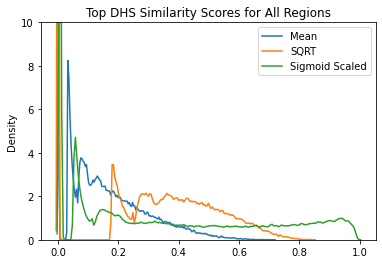

In [6]:
fig = plt.figure()
fig.patch.set_facecolor('white')
    
sns.kdeplot(DHS_top_vals[:, 0], bw_adjust=0.1)
sns.kdeplot(DHS_top_sqrt_vals[:, 0], bw_adjust=0.1)
sns.kdeplot(DHS_top_sqrtsig_vals[:, 0], bw_adjust=0.1)

plt.ylim([0, 10])
plt.legend(['Mean', 'SQRT', 'Sigmoid Scaled'])
plt.title('Top DHS Similarity Scores for All Regions')

In [13]:
# percentiles from z scores
TF_per_arr = np.where(TF_z_arr==0, 0, stats.norm.cdf(TF_z_arr))
# convolution with mean
TF_per_conv_mean = np.matmul(TF_per_arr, TF_per_arr.T) / len(TF_per_arr[0])
# find top 1000 regions
TF_top_regions, TF_top_vals = find_top_regions(TF_per_conv_mean)
del TF_per_conv_mean
# sigmoid scale the top 1000 values between 0 and 1
TF_top_sqrt_vals = np.sqrt(TF_top_vals)
TF_top_sqrtsig_vals = sigmoid_func_post(TF_top_sqrt_vals)

Text(0.5, 1.0, 'Top TF Similarity Scores for All Regions')

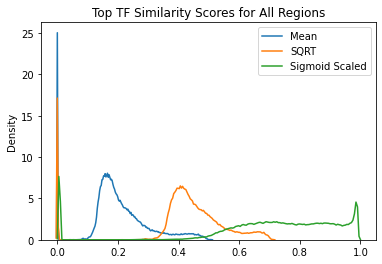

In [15]:
fig = plt.figure()
fig.patch.set_facecolor('white')
    
sns.kdeplot(TF_top_vals[:, 0], bw_adjust=0.1)
sns.kdeplot(TF_top_sqrt_vals[:, 0], bw_adjust=0.1)
sns.kdeplot(TF_top_sqrtsig_vals[:, 0], bw_adjust=0.1)

plt.legend(['Mean', 'SQRT', 'Sigmoid Scaled'])
plt.title('Top TF Similarity Scores for All Regions')

In [19]:
# scale mean scores between 0 and 1
epi_mean_sig_arr = sigmoid_func_pre(epi_mean_arr)
# convolution with mean
epi_mean_conv_mean = np.matmul(epi_mean_sig_arr, epi_mean_sig_arr.T) / len(epi_mean_sig_arr[0])
# find top 1000 regions
epi_top_regions, epi_top_vals = find_top_regions(epi_mean_conv_mean)
del epi_mean_conv_mean
# sigmoid scale the top 1000 values between 0 and 1
epi_top_sqrt_vals = np.sqrt(epi_top_vals)
epi_top_sqrtsig_vals = sigmoid_func_post(epi_top_sqrt_vals)

Text(0.5, 1.0, 'Top Epilogos Similarity Scores for All Regions')

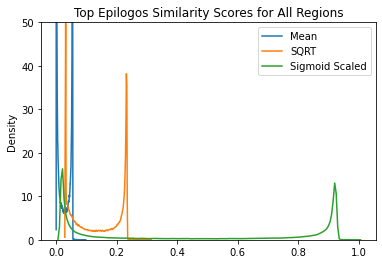

In [21]:
fig = plt.figure()
fig.patch.set_facecolor('white')
    
sns.kdeplot(epi_top_vals[:, 0], bw_adjust=0.1)
sns.kdeplot(epi_top_sqrt_vals[:, 0], bw_adjust=0.1)
sns.kdeplot(epi_top_sqrtsig_vals[:, 0], bw_adjust=0.1)

plt.ylim([0, 50])
plt.legend(['Mean', 'SQRT', 'Sigmoid Scaled'])
plt.title('Top Epilogos Similarity Scores for All Regions')

**Fusion Results**

In [22]:
num_regions = len(DHS_top_sqrtsig_vals)

top_100_regions_split_by_contributions = []
top_100_fusion_scores = []

for i in range(num_regions):
    DHS_arr = np.zeros(num_regions)
    TF_arr = np.zeros(num_regions)
    epi_arr = np.zeros(num_regions)

    #setting similarity values for each region
    DHS_arr[DHS_top_regions[i]] = DHS_top_sqrtsig_vals[i]
    TF_arr[TF_top_regions[i]] = TF_top_sqrtsig_vals[i]
    epi_arr[epi_top_regions[i]] = epi_top_sqrtsig_vals[i]
    
    #fusion score
    fusion_i = 1 - ((1 - DHS_arr) * (1 - TF_arr) * (1 - epi_arr))
    
    #how many of top 100 are from each metric
    top_100 = np.argsort(-fusion_i)[:100]
    top_100_fusion_scores.append(-np.sort(-fusion_i)[:100])
    
    all3 = len(top_100[np.isin(top_100, DHS_top_regions[i]) & 
                       np.isin(top_100, TF_top_regions[i]) & 
                       np.isin(top_100, epi_top_regions[i])])
    notDHS = len(top_100[~np.isin(top_100, DHS_top_regions[i]) & 
                         np.isin(top_100, TF_top_regions[i]) & 
                         np.isin(top_100, epi_top_regions[i])])
    notTF = len(top_100[np.isin(top_100, DHS_top_regions[i]) & 
                        ~np.isin(top_100, TF_top_regions[i]) & 
                        np.isin(top_100, epi_top_regions[i])])
    notepi = len(top_100[np.isin(top_100, DHS_top_regions[i]) & 
                         np.isin(top_100, TF_top_regions[i]) & 
                         ~np.isin(top_100, epi_top_regions[i])])
    dhsonly = len(top_100[np.isin(top_100, DHS_top_regions[i]) & 
                          ~np.isin(top_100, TF_top_regions[i]) & 
                          ~np.isin(top_100, epi_top_regions[i])])
    TFonly = len(top_100[~np.isin(top_100, DHS_top_regions[i]) & 
                         np.isin(top_100, TF_top_regions[i]) & 
                         ~np.isin(top_100, epi_top_regions[i])])
    epionly = len(top_100[~np.isin(top_100, DHS_top_regions[i]) & 
                          ~np.isin(top_100, TF_top_regions[i]) & 
                          np.isin(top_100, epi_top_regions[i])])

    top_100_regions_split_by_contributions.append([all3, notDHS, notTF, notepi, dhsonly, TFonly, epionly])
top_100_regions_split_by_contributions = np.array(top_100_regions_split_by_contributions)
top_100_fusion_scores = np.array(top_100_fusion_scores)

In [23]:
violin_y = top_100_regions_split_by_contributions.flatten('F')
violin_x = (np.ones(top_100_regions_split_by_contributions.shape) * np.arange(7)).flatten('F')

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


Text(0.5, 1.0, 'Contributions to Top 100 Similar Regions from each Metric Combination for All Query Regions')

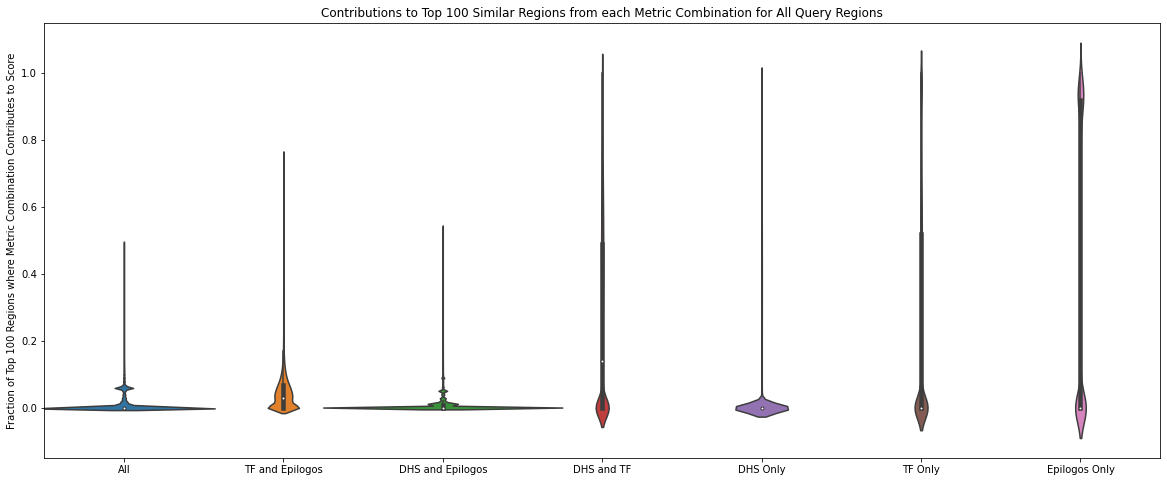

In [35]:
violin_y = top_100_regions_split_by_contributions.flatten('F') / 100
violin_x = (np.ones(top_100_regions_split_by_contributions.shape) * np.arange(7)).flatten('F')

fig = plt.figure(figsize=(20, 8))
fig.patch.set_facecolor('white')

s = sns.violinplot(violin_x, violin_y, width=1.5)

plt.xticks(np.arange(7), 
           ['All', 'TF and Epilogos', 'DHS and Epilogos', 'DHS and TF', 'DHS Only', 'TF Only', 'Epilogos Only'])

plt.ylabel('Fraction of Top 100 Regions where Metric Combination Contributes to Score')
plt.title('Contributions to Top 100 Similar Regions from each Metric Combination for All Query Regions')

In [69]:
top_100_regions_split_by_contributions[8271]

array([ 2,  4,  0, 49,  0, 45,  0])

In [57]:
f = open(regions_path, 'r')
regions = f.readlines()
f.close()

In [66]:
top_100_fusion_scores
# track individual metrics as well

array([[0.99754772, 0.99470828, 0.95389983, ..., 0.94048153, 0.94046191,
        0.94041653],
       [0.9850495 , 0.98383235, 0.9831706 , ..., 0.9255453 , 0.9255453 ,
        0.9255453 ],
       [0.98834062, 0.98676438, 0.98623534, ..., 0.92558688, 0.92558688,
        0.92558688],
       ...,
       [0.02704308, 0.02646709, 0.02607738, ..., 0.01408956, 0.01408882,
        0.01408718],
       [0.02704308, 0.02646709, 0.02607738, ..., 0.01408956, 0.01408882,
        0.01408718],
       [0.02704308, 0.02646709, 0.02607738, ..., 0.01408956, 0.01408882,
        0.01408718]])